In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, LSTM, Dense, Attention,
    Concatenate, RepeatVector, TimeDistributed
)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [2]:
train = pd.read_csv("../data/rossmann_train.csv")

train["Date"] = pd.to_datetime(train["Date"])
train = train.sort_values(["Store", "Date"])

daily_sales = train.groupby("Date")["Sales"].sum()

print("Dataset shape:", train.shape)
print("Daily sales shape:", daily_sales.shape)
print(daily_sales.head())

C:\Users\pritd\AppData\Local\Temp\ipykernel_19676\1077257437.py:1: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  train = pd.read_csv("../data/rossmann_train.csv")


Dataset shape: (1017209, 9)
Daily sales shape: (942,)
Date
2013-01-01      97235
2013-01-02    6949829
2013-01-03    6347820
2013-01-04    6638954
2013-01-05    5951593
Name: Sales, dtype: int64


In [3]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

sales_scaled = scaler.fit_transform(
    daily_sales.values.reshape(-1, 1)
)

print("Scaled shape:", sales_scaled.shape)

Scaled shape: (942, 1)


In [4]:
X = []
y = []

input_days = 14
output_days = 7

for i in range(input_days, len(sales_scaled) - output_days + 1):
    X.append(sales_scaled[i-input_days:i])
    y.append(sales_scaled[i:i+output_days])

X = np.array(X)
y = np.array(y)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (922, 14, 1)
y shape: (922, 7, 1)


In [5]:
split = int(len(X) * 0.8)

X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (737, 14, 1)
X_test: (185, 14, 1)
y_train: (737, 7, 1)
y_test: (185, 7, 1)


In [6]:
from tensorflow.keras.layers import Input, LSTM

encoder_inputs = Input(shape=(14, 1))

encoder_lstm = LSTM(
    64,
    return_sequences=True,
    return_state=True
)

encoder_outputs, state_h, state_c = encoder_lstm(encoder_inputs)

print("Encoder output shape:", encoder_outputs.shape)

Encoder output shape: (None, 14, 64)


In [7]:
from tensorflow.keras.layers import RepeatVector

decoder_inputs = RepeatVector(7)(state_h)

decoder_lstm = LSTM(
    64,
    return_sequences=True
)

decoder_outputs = decoder_lstm(
    decoder_inputs,
    initial_state=[state_h, state_c]
)

print("Decoder output shape:", decoder_outputs.shape)

Decoder output shape: (None, 7, 64)


In [8]:
from tensorflow.keras.layers import Attention, Concatenate, TimeDistributed, Dense

attention = Attention()

context = attention([
    decoder_outputs,
    encoder_outputs
])

combined = Concatenate(axis=-1)([
    decoder_outputs,
    context
])

outputs = TimeDistributed(Dense(1))(combined)

In [9]:
from tensorflow.keras.models import Model

model = Model(
    inputs=encoder_inputs,
    outputs=outputs
)

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 14, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ [(None, 14, 64),  │     16,896 │ input_layer[0][0] │
│                     │ (None, 64),       │            │                   │
│                     │ (None, 64)]       │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ repeat_vector       │ (None, 7, 64)     │          0 │ lstm[0][1]        │
│ (RepeatVector)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ (None, 7, 64)     │     33,024 │ repeat_vector[0]… │
│                     │                   │            │ lstm[0][1],       │
│                     │                   │            │ lstm[0][2]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention           │ (None, 7, 64)     │          0 │ lstm_1[0][0],     │
│ (Attention)         │                   │            │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 7, 128)    │          0 │ lstm_1[0][0],     │
│ (Concatenate)       │                   │            │ attention[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time_distributed    │ (None, 7, 1)      │        129 │ concatenate[0][0] │
│ (TimeDistributed)   │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 50,049 (195.50 KB)

 Trainable params: 50,049 (195.50 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 4s 34ms/step - loss: 0.0881 - mae: 0.2337 - val_loss: 0.0474 - val_mae: 0.1735
Epoch 2/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0419 - mae: 0.1569 - val_loss: 0.0472 - val_mae: 0.1670
Epoch 3/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0400 - mae: 0.1454 - val_loss: 0.0465 - val_mae: 0.1675
Epoch 4/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0398 - mae: 0.1438 - val_loss: 0.0464 - val_mae: 0.1678
Epoch 5/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0398 - mae: 0.1443 - val_loss: 0.0464 - val_mae: 0.1672
Epoch 6/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0397 - mae: 0.1441 - val_loss: 0.0463 - val_mae: 0.1669
Epoch 7/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0395 - mae: 0.1434 - val_loss: 0.0463 - val_mae: 0.1671
Epoch 8/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0396 - mae: 0.1439 - val_loss: 0.0463 - val_mae: 0.1682
Epoch 9/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.039

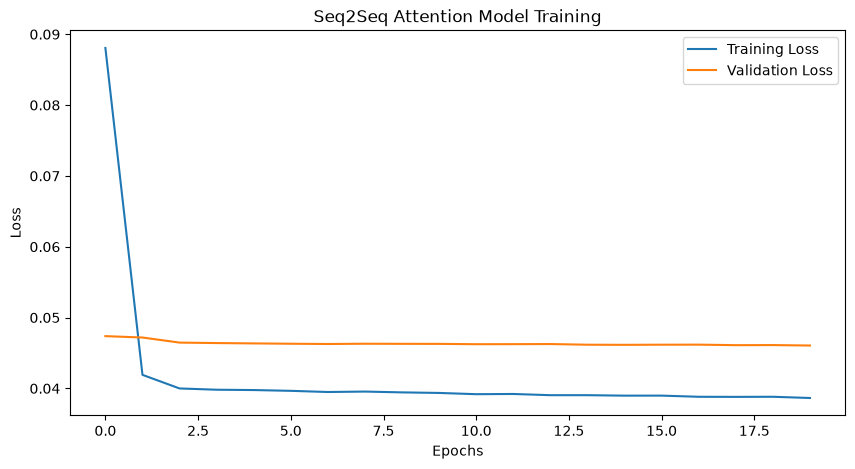

In [11]:
plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Seq2Seq Attention Model Training")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [12]:
test_loss, test_mae = model.evaluate(X_test, y_test)

print("Test Loss:", test_loss)
print("Test MAE:", test_mae)

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0432 - mae: 0.1603
Test Loss: 0.04324165731668472
Test MAE: 0.16029302775859833


In [13]:
predictions = model.predict(X_test)

predictions_actual = scaler.inverse_transform(
    predictions.reshape(-1, 1)
).reshape(-1, 7)

actual_values = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).reshape(-1, 7)

print("Predictions shape:", predictions_actual.shape)
print("Actual shape:", actual_values.shape)

6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 77ms/step
Predictions shape: (185, 7)
Actual shape: (185, 7)


In [14]:

from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(
    actual_values.flatten(),
    predictions_actual.flatten()
)

rmse = np.sqrt(mean_squared_error(
    actual_values.flatten(),
    predictions_actual.flatten()
))

print("Day 10 MAE:", mae)
print("Day 10 RMSE:", rmse)

Day 10 MAE: 2488759.5880308882
Day 10 RMSE: 3228639.0064597945


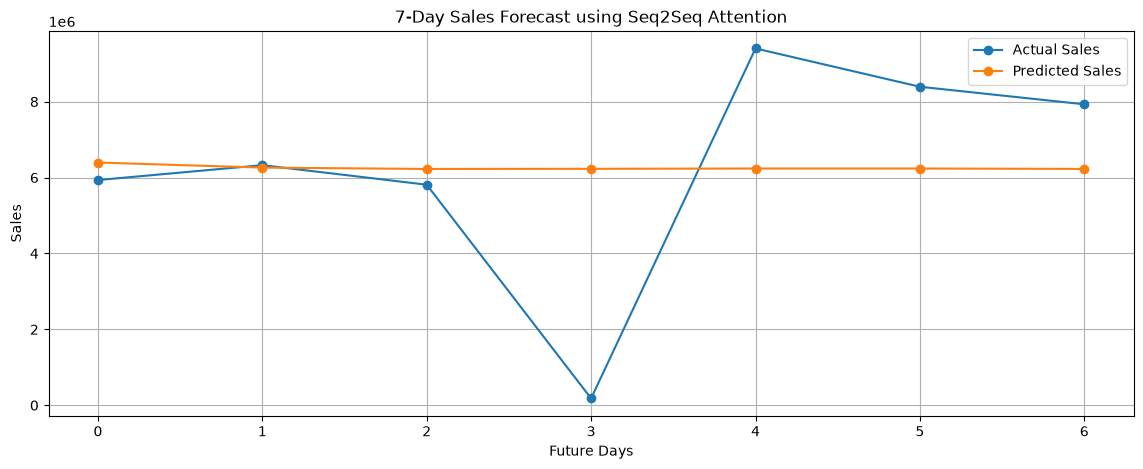

In [15]:
plt.figure(figsize=(14, 5))

plt.plot(actual_values[0], marker="o", label="Actual Sales")
plt.plot(predictions_actual[0], marker="o", label="Predicted Sales")

plt.title("7-Day Sales Forecast using Seq2Seq Attention")
plt.xlabel("Future Days")
plt.ylabel("Sales")
plt.xticks(range(7))
plt.legend()
plt.grid()
plt.show()

In [18]:
attention_model = Model(
    inputs=encoder_inputs,
    outputs=attention_scores
)

ValueError: Output with path `` is not connected to `inputs`

In [19]:
from tensorflow.keras.layers import Input, RepeatVector, Attention
from tensorflow.keras.models import Model

viz_input = Input(shape=(14, 1))

enc_out, h, c = encoder_lstm(viz_input)

dec_input = RepeatVector(7)(h)

dec_out = decoder_lstm(
    dec_input,
    initial_state=[h, c]
)

viz_attention = Attention()

context, scores = viz_attention(
    [dec_out, enc_out],
    return_attention_scores=True
)

attention_model = Model(
    inputs=viz_input,
    outputs=scores
)

weights = attention_model.predict(X_test[:1])

print("Attention weights shape:", weights.shape)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Attention weights shape: (1, 7, 14)


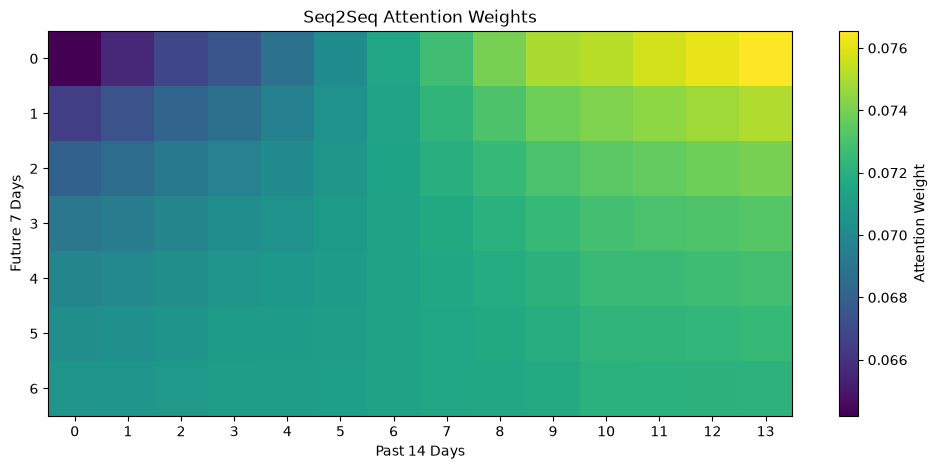

In [20]:

plt.figure(figsize=(12, 5))

plt.imshow(weights[0], cmap="viridis", aspect="auto")
plt.colorbar(label="Attention Weight")

plt.xlabel("Past 14 Days")
plt.ylabel("Future 7 Days")
plt.title("Seq2Seq Attention Weights")

plt.xticks(range(14))
plt.yticks(range(7))
plt.show()

In [21]:
comparison = pd.DataFrame({
    "Model": ["Day 9 LSTM", "Day 10 Seq2Seq Attention"],
    "Forecast Horizon": ["1 Day", "7 Days"],
    "MAE": [2488759, mae],
    "RMSE": [3228639, rmse]
})

comparison

,Model,Forecast Horizon,MAE,RMSE
0,Day 9 LSTM,1 Day,2.488759e+06,3.228639e+06
1,Day 10 Seq2Seq Attention,7 Days,2.488760e+06,3.228639e+06


In [22]:
from pathlib import Path
import joblib

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(exist_ok=True)

model.save(MODEL_DIR / "rossmann_seq2seq_attention_day10.keras")

joblib.dump(
    scaler,
    MODEL_DIR / "rossmann_seq2seq_scaler_day10.pkl"
)

print("Day 10 model and scaler saved!")

Day 10 model and scaler saved!
